# Instituto de Ciências Matemáticas e de Computação - ICMC
# Universidade de São Paulo - USP
## Tarefa: Exploração de Dados
## Aluna: Luiza Rodrigues Cardoso - 14593332
**Objetivo:** Desenvolver um relatório de exploração em um conjunto de dados real aplicando estatística descritiva e visualização.

Para esta atividade, utilizaremos o **California Housing Dataset**, um conjunto de dados com informações sobre distritos habitacionais na Califórnia (renda média, idade das casas, número de cômodos, localização geográfica, etc.).

Faça uma cópia desse notebook, insira seu nome e número USP e entregue o notebook (aquivo .ipynb) no e-disciplinas.

Tarefa Individual!

Prazo de entrega: 25/09/2026

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

# Carregando o conjunto de dados
california = fetch_california_housing()
df = pd.DataFrame(california.data, columns=california.feature_names)
df['MedHouseVal'] = california.target

# Visualizando as 5 primeiras instâncias
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


### Parte 1: Caracterização dos Dados
*Nesta etapa, você deve documentar a natureza das variáveis do DataFrame carregado acima.*
- Identifique os atributos e classifique-os em simbólicos ou numéricos.
- Determine se são discretos (número enumerável) ou contínuos (número infinito de valores).

#### Identificando e classificando os atributos

- Qualitativo / Simbólico:

    - Nominal: Categorias sem ordem natural (nao tem neste dataset).
    - Ordinal: Categorias que possuem uma ordem lógica ou hierarquia (nao tem neste dataset).

- Quantitativo / Numérico:

    - Intervalar: Variáveis numéricas onde a diferença tem significado, mas o zero é arbitrário (coordenadas geograficas {Latitude, Longitude}).

    - Racional (Razão): Variáveis numéricas com um zero absoluto real (o zero significa ausência total da grandeza) (ex: MedInc [renda mediana], HouseAge [idade do imóvel], AveRooms [média de quartos], AveBedrms [média de banheiros],	Population [população] ,AveOccup [méida de ocupação da região],	MedHouseVal [valor médio do imóvel]).

In [22]:
from IPython.display import display, Markdown

display(Markdown('### 1. Amostra Inicial dos Dados'))
display(df.head())

#classficiando conforme descrito acima
classificando = {
    'MedInc': 'Quantitativa Racional',
    'HouseAge': 'Quantitativa Racional',
    'AveRooms':'Quantitativa Racional',
    'AveBedrms':'Quantitativa Racional',
    'Population': 'Quantitativa Racional',
    'AveOccup': 'Quantitativa Racional',
    'Latitude':'Quantitativa Intervalar',
    'Longitude': 'Quantitativa Intervalar',
    'MedHouseVal' :'Quantitativa Racional'
}

aux = []
for col in df.columns:
  tipoPandas = df[col].dtype
  classe = classificando.get(col, 'Não classificado')
  aux.append(
            {'Coluna': col,
             'Tipo Pandas' :str(tipoPandas),
             'Classificação Fina': classe}
             )

df_tipoDetalhado = pd.DataFrame(aux)

display(Markdown('### 2. Visão Detalhada das Colunas e suas classificações'))
# Aplicando estilo CSS para evitar que o texto seja cortado e permitir quebra de linha
estilo_tabela = df_tipoDetalhado.style.set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'left'), ('font-weight', 'bold'), ('background-color', '#f2f2f2')]},
    {'selector': 'td', 'props': [('text-align', 'left'), ('white-space', 'normal'), ('max-width', '400px')]}
])

display(estilo_tabela)

### 1. Amostra Inicial dos Dados

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### 2. Visão Detalhada das Colunas e suas classificações

,Coluna,Tipo Pandas,Classificação Fina
0,MedInc,float64,Quantitativa Racional
1,HouseAge,float64,Quantitativa Racional
2,AveRooms,float64,Quantitativa Racional
3,AveBedrms,float64,Quantitativa Racional
4,Population,float64,Quantitativa Racional
5,AveOccup,float64,Quantitativa Racional
6,Latitude,float64,Quantitativa Intervalar
7,Longitude,float64,Quantitativa Intervalar
8,MedHouseVal,float64,Quantitativa Racional


#### Identificando se são Discretos ou Contínuos

- Discretos: números finitos ou numeráveis (incluem os binários também)
- Contínups: números infinitos, comos os num reais.

In [21]:
#classficiando ( escala de medida + quantidade de valores)
classificando = {
    'MedInc': {
      'escala': 'Quantitativa Racional',
      'quantidade': 'Contínuo (valores reais)'
    },
    'HouseAge':
     {'escala': 'Quantitativa Racional',
    'quantidade': 'Discreto (valores inteiros)'
    },
    'AveRooms':
    {'escala': 'Quantitativa Racional',
    'quantidade': 'Contínuo (valores reais)'
    },
    'AveBedrms':
     {'escala': 'Quantitativa Racional',
    'quantidade': 'Contínuo (valores reais)'
    },
    'Population':
    {'escala': 'Quantitativa Racional',
    'quantidade': 'Discreto (valores inteiros)'
    },
    'AveOccup':
     {'escala': 'Quantitativa Racional',
    'quantidade': 'Contínuo (valores reais)'
    },
    'Latitude':
    {'escala':'Quantitativa Intervalar',
     'quantidade': 'Contínuo (valores reais)'},
    'Longitude':
    {'escala':'Quantitativa Intervalar',
     'quantidade': 'Contínuo (valores reais)'},
    'MedHouseVal':
     {'escala': 'Quantitativa Racional',
    'quantidade': 'Contínuo (valores reais)'
    }
}

aux = []
for col in df.columns:
  tipoPandas = df[col].dtype
  info = classificando.get(col, {'escala': 'Não classificado', 'quantidade': 'Não classificado'})
  aux.append(
            {'Coluna': col,
             'Tipo Pandas' :str(tipoPandas),
             'Escala': info['escala'],
             'Quantidade de Valores': info['quantidade']}
             )

df_tipoDetalhado = pd.DataFrame(aux)

display(Markdown('### 2. Visão Detalhada das Colunas e suas classificações'))
# Aplicando estilo CSS para evitar que o texto seja cortado e permitir quebra de linha
estilo_tabela = df_tipoDetalhado.style.set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'left'), ('font-weight', 'bold'), ('background-color', '#f2f2f2')]},
    {'selector': 'td', 'props': [('text-align', 'left'), ('white-space', 'normal'), ('max-width', '300px')]}
])

display(estilo_tabela)

### 2. Visão Detalhada das Colunas e suas classificações

,Coluna,Tipo Pandas,Escala,Quantidade de Valores
0,MedInc,float64,Quantitativa Racional,Contínuo (valores reais)
1,HouseAge,float64,Quantitativa Racional,Discreto (valores inteiros)
2,AveRooms,float64,Quantitativa Racional,Contínuo (valores reais)
3,AveBedrms,float64,Quantitativa Racional,Contínuo (valores reais)
4,Population,float64,Quantitativa Racional,Discreto (valores inteiros)
5,AveOccup,float64,Quantitativa Racional,Contínuo (valores reais)
6,Latitude,float64,Quantitativa Intervalar,Contínuo (valores reais)
7,Longitude,float64,Quantitativa Intervalar,Contínuo (valores reais)
8,MedHouseVal,float64,Quantitativa Racional,Contínuo (valores reais)


### Parte 2: Análise Univariada (Estatística Descritiva)
*Para os atributos numéricos, programe e documente as seguintes métricas:*
1. **Medidas de Localidade:** Calcule a tendência central utilizando média, mediana e moda.
2. **Tratamento de Extremos:** Aplique e explique a média podada e a Winsorização.
3. **Medidas de Espalhamento:** Calcule o intervalo (máximo - mínimo), variância (correção de Bessel n-1) e desvio padrão.
4. **Quartis e Outliers:** Encontre Q1, Q2, Q3 e o Intervalo Interquartil (IQR). Calcule a Cerca Inferior e Cerca Superior para identificar os outliers.
5. **Momentos da Distribuição:** Calcule a Obliquidade (Skewness) para avaliar simetria e a Curtose (Kurtosis) para avaliar o achatamento da distribuição.

#### 1. **Medidas de Localidade:** Calcule a tendência central utilizando média

In [31]:
#calculo da média, mediana e moda dos atributos numéricos
aux = []
for col in df.columns:

  #removendo os valores nulos
  df_tmp =  df[col].dropna()


  media = df_tmp.mean()
  mediana =  df_tmp.median()
  moda = df_tmp.mode().tolist()

  aux.append({'coluna': col,
              'media': media,
              'mediana': mediana,
              'moda': moda}
             )

pdMedLocal = pd.DataFrame(aux)
pdMedLocal

,coluna,media,mediana,moda
0,MedInc,3.870671,3.534800,"[3.125, 15.0001]"
1,HouseAge,28.639486,29.000000,[52.0]
2,AveRooms,5.429000,5.229129,[5.0]
3,AveBedrms,1.096675,1.048780,[1.0]
4,Population,1425.476744,1166.000000,[891.0]
5,AveOccup,3.070655,2.818116,[3.0]
6,Latitude,35.631861,34.260000,[34.06]
7,Longitude,-119.569704,-118.490000,[-118.31]
8,MedHouseVal,2.068558,1.797000,[5.00001]


#### 2. **Tratamento de Extremos:** Aplique e explique a média podada e a Winsorização.

  ##### 2.1 Media Podada
Descarta uma porcentagem p dos dados nas extremidades(menores e maiores valores) antes de calcular a média com o que sobrou no meio.


In [30]:
from scipy.stats  import trim_mean


aux = []
for col in df.columns:
  #removendo os valores nulos
  df_tmp =  df[col].dropna()

  media =  df_tmp.mean()
  #calculando a media podada com p = 0.1
  p = 0.10
  mediaPodada = trim_mean(df_tmp, proportiontocut=p)


  aux.append({'Coluna': col,
              'Média Tradicional': media,
              'Média Podada': mediaPodada}
             )

pdMedias = pd.DataFrame(aux)

display(Markdown("### Comparação: Média Tradicional vs. Média Podada (com p = 10%)"))
display(pdMedias)

### Comparação: Média Tradicional vs. Média Podada (com p = 10%)

,Coluna,Média Tradicional,Média Podada
0,MedInc,3.870671,3.654012
1,HouseAge,28.639486,28.494549
2,AveRooms,5.429000,5.252606
3,AveBedrms,1.096675,1.053191
4,Population,1425.476744,1256.512900
5,AveOccup,3.070655,2.857799
6,Latitude,35.631861,35.508249
7,Longitude,-119.569704,-119.518129
8,MedHouseVal,2.068558,1.927730


##### 2.2 Winsorização

Enquanto a média podada descarta os valores que estão nos extremos, a Winsorização substitui esses valores extremos pelos limites aceitáveis mais próximos (geralmente definidos por percentis, como 5% e 95%, ou 10% e 90%).

  **Vantagem prática:** Em vez de perder linhas de dados (o que acontece quando você descarta os extremos na média podada), você mantém o tamanho total da amostra, mas "amacia" o impacto dos outliers empurrando-os para dentro de um limite tolerável."


In [29]:
aux = []

for col in df.select_dtypes(include='number').columns:

    # retirando os nulos
    df_tmp = df[col].dropna()

    # percentis
    p_inf = df_tmp.quantile(0.05)
    p_sup = df_tmp.quantile(0.95)

    # winsorização
    df_clipado = df_tmp.clip(lower=p_inf, upper=p_sup)

    # adicionando cada estatística como uma linha
    aux.extend([
        {
            'Coluna': col,
            'Estatística': 'Mínimo',
            'Original': df_tmp.min(),
            'Winsorizada': df_clipado.min()
        },
        {
            'Coluna': col,
            'Estatística': 'Máximo',
            'Original': df_tmp.max(),
            'Winsorizada': df_clipado.max()
        },
        {
            'Coluna': col,
            'Estatística': 'Média',
            'Original': df_tmp.mean(),
            'Winsorizada': df_clipado.mean()
        }
    ])

df_comparacao_winsor = pd.DataFrame(aux)

display(
    Markdown("### Efeito da Winsorização nas Variáveis Numéricas")
)

display(df_comparacao_winsor)


### Efeito da Winsorização nas Variáveis Numéricas

,Coluna,Estatística,Original,Winsorizada
0,MedInc,Mínimo,0.499900,1.600570
1,MedInc,Máximo,15.000100,7.300305
2,MedInc,Média,3.870671,3.787417
3,HouseAge,Mínimo,1.000000,8.000000
4,HouseAge,Máximo,52.000000,52.000000
5,HouseAge,Média,28.639486,28.769186
6,AveRooms,Mínimo,0.846154,3.432330
7,AveRooms,Máximo,141.909091,7.640247
8,AveRooms,Média,5.429000,5.300188
9,AveBedrms,Mínimo,0.333333,0.939109


#### 3. **Medidas de Espalhamento:** Calcule o intervalo (máximo - mínimo), variância (correção de Bessel n-1) e desvio padrão.

In [32]:
# cálculo do intervalo, variância e desvio padrão
aux = []

for col in df.select_dtypes(include='number').columns:

    # retirando os nulos
    df_tmp = df[col].dropna()

    # cálculo das medidas
    intervalo = df_tmp.max() - df_tmp.min()
    variancia = df_tmp.var(ddof=1)
    desvio_padrao = df_tmp.std(ddof=1)

    aux.append({
        'Coluna': col,
        'Intervalo': intervalo,
        'Variância (n-1)': variancia,
        'Desvio Padrão': desvio_padrao
    })

df_dispersao = pd.DataFrame(aux)

display(Markdown("### Medidas de Dispersão"))
display(df_dispersao)


### Medidas de Dispersão

,Coluna,Intervalo,Variância (n-1),Desvio Padrão
0,MedInc,14.500200,3.609323e+00,1.899822
1,HouseAge,51.000000,1.583963e+02,12.585558
2,AveRooms,141.062937,6.121533e+00,2.474173
3,AveBedrms,33.733333,2.245915e-01,0.473911
4,Population,35679.000000,1.282470e+06,1132.462122
5,AveOccup,1242.641026,1.078700e+02,10.386050
6,Latitude,9.410000,4.562293e+00,2.135952
7,Longitude,10.040000,4.014139e+00,2.003532
8,MedHouseVal,4.850020,1.331615e+00,1.153956


In [3]:
# TODO: Escolha atributos de interesse do dataset e calcule as estatísticas descritivas.
from scipy import stats
# Dica: utilize stats.trim_mean, stats.mstats.winsorize, stats.skew, stats.kurtosis


##### 4. **Quartis e Outliers:** Encontre Q1, Q2, Q3 e o Intervalo Interquartil (IQR). Calcule a Cerca Inferior e Cerca Superior para identificar os outliers.

In [39]:

aux = []

for col in df.select_dtypes(include='number').columns:

    # retirando os nulos
    df_tmp = df[col].dropna()

    # Calculando os Quartis usando a função quantile do pandas
    # Q1 = 25%, Q2 = 50% (mediana), Q3 = 75%
    quartis = df_tmp.quantile([0.25, 0.50, 0.75])

    q1 = quartis.loc[0.25]
    q2 = quartis.loc[0.50]
    q3 = quartis.loc[0.75]

    #calculo do intervalo quartil
    intervalo = q3 - q1

    # Calcula das cercas
    cerca_inferior = q1 - 1.5 * intervalo
    cerca_superior = q3 + 1.5 * intervalo

    #cont outliers
    outliers = df_tmp[
        (df_tmp < cerca_inferior) |
        (df_tmp > cerca_superior)
    ]

    aux.append({
        'Coluna': col,
        'Intervalo': intervalo,
        'Q1 (25% - Inferior)': q1,
        'Q2 (50% - Mediana)': q2,
        'Q3 (75% - Superior)': q3,
        'Cerca Inferior': cerca_inferior,
        'Cerca Superior': cerca_superior,
        'Outliers': len(outliers)
    })

df_quartis = pd.DataFrame(aux)

display(Markdown("### Medidas dos Quartis"))
display(df_quartis)


### Medidas dos Quartis

,Coluna,Intervalo,Q1 (25% - Inferior),Q2 (50% - Mediana),Q3 (75% - Superior),Cerca Inferior,Cerca Superior,Outliers
0,MedInc,2.179850,2.563400,3.534800,4.743250,-0.706375,8.013025,681
1,HouseAge,19.000000,18.000000,29.000000,37.000000,-10.500000,65.500000,0
2,AveRooms,1.611665,4.440716,5.229129,6.052381,2.023219,8.469878,511
3,AveBedrms,0.093447,1.006079,1.048780,1.099526,0.865909,1.239697,1424
4,Population,938.000000,787.000000,1166.000000,1725.000000,-620.000000,3132.000000,1196
5,AveOccup,0.852520,2.429741,2.818116,3.282261,1.150961,4.561041,711
6,Latitude,3.780000,33.930000,34.260000,37.710000,28.260000,43.380000,0
7,Longitude,3.790000,-121.800000,-118.490000,-118.010000,-127.485000,-112.325000,0
8,MedHouseVal,1.451250,1.196000,1.797000,2.647250,-0.980875,4.824125,1071


##### 5. **Momentos da Distribuição:** Calcule a Obliquidade (Skewness) para avaliar simetria e a Curtose (Kurtosis) para avaliar o achatamento da distribuição.

In [41]:
aux = []

for col in df.select_dtypes(include='number').columns:

    # retirando os nulos
    df_tmp = df[col].dropna()

    # Calculando a obliquidade (Skewness)
    skewness = stats.skew(df_tmp)

    # Interpretando a Skewness
    if skewness > 0:
        interpretacao_skew = "Assimetria positiva (cauda para a direita)"
    elif skewness < 0:
        interpretacao_skew = "Assimetria negativa (cauda para a esquerda)"
    else:
        interpretacao_skew = "Distribuição aproximadamente simétrica"

    # Calculando a curtose (Kurtosis)
    kurtosis = stats.kurtosis(df_tmp)

    # Interpretando a Kurtosis
    if kurtosis > 0:
        interpretacao_kurt = "Caudas mais pesadas que a distribuição normal"
    elif kurtosis < 0:
        interpretacao_kurt = "Caudas mais leves que a distribuição normal"
    else:
        interpretacao_kurt = "Curtose semelhante à distribuição normal"

    aux.append({
        'Coluna': col,
        'Skewness (Obliquidade)': skewness,
        'Interpretação Skewness': interpretacao_skew,
        'Kurtosis (Curtose)': kurtosis,
        'Interpretação Kurtosis': interpretacao_kurt
    })

df_skew_kurt = pd.DataFrame(aux)

display(Markdown("### Obliquidade e Curtose"))
display(df_skew_kurt)

### Obliquidade e Curtose

,Coluna,Skewness (Obliquidade),Interpretação Skewness,Kurtosis (Curtose),Interpretação Kurtosis
0,MedInc,1.646537,Assimetria positiva (cauda para a direita),4.951034,Caudas mais pesadas que a distribuição normal
1,HouseAge,0.060326,Assimetria positiva (cauda para a direita),-0.800726,Caudas mais leves que a distribuição normal
2,AveRooms,20.696365,Assimetria positiva (cauda para a direita),879.139966,Caudas mais pesadas que a distribuição normal
3,AveBedrms,31.314680,Assimetria positiva (cauda para a direita),1636.315218,Caudas mais pesadas que a distribuição normal
4,Population,4.935500,Assimetria positiva (cauda para a direita),73.535009,Caudas mais pesadas que a distribuição normal
5,AveOccup,97.632465,Assimetria positiva (cauda para a direita),10648.430334,Caudas mais pesadas que a distribuição normal
6,Latitude,0.465919,Assimetria positiva (cauda para a direita),-1.117780,Caudas mais leves que a distribuição normal
7,Longitude,-0.297780,Assimetria negativa (cauda para a esquerda),-1.330121,Caudas mais leves que a distribuição normal
8,MedHouseVal,0.977692,Assimetria positiva (cauda para a direita),0.327500,Caudas mais pesadas que a distribuição normal


### Parte 3: Análise Multivariada
*Foco em como os múltiplos atributos se relacionam entre si.*
1. **Matriz de Covariância:** Construa a matriz e analise se os relacionamentos são diretos ou inversos.
2. **Matriz de Correlação:** Calcule a correlação de Pearson para eliminar a influência das faixas de valores e extrair a força real da relação linear entre pares.

In [58]:
# TODO: Calcule e imprima as matrizes de covariância e correlação. (Dica: métodos .cov() e .corr() do pandas)

# matriz de covariância
matriz_covar = df.cov()
display(Markdown("### Matriz de Covariância"))
display(matriz_covar)



### Matriz de Covariância

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,3.609323,-2.846140,1.536568,-0.055858,1.040098e+01,0.370289,-0.323860,-0.057765,1.508475
HouseAge,-2.846140,158.396260,-4.772882,-0.463718,-4.222271e+03,1.724298,0.300346,-2.728244,1.533988
AveRooms,1.536568,-4.772882,6.121533,0.993868,-2.023337e+02,-0.124689,0.562235,-0.136518,0.433826
AveBedrms,-0.055858,-0.463718,0.993868,0.224592,-3.552723e+01,-0.030424,0.070575,0.012670,-0.025539
Population,10.400979,-4222.270582,-202.333712,-35.527225,1.282470e+06,821.712002,-263.137814,226.377839,-32.212487
AveOccup,0.370289,1.724298,-0.124689,-0.030424,8.217120e+02,107.870026,0.052492,0.051519,-0.284494
Latitude,-0.323860,0.300346,0.562235,0.070575,-2.631378e+02,0.052492,4.562293,-3.957054,-0.355326
Longitude,-0.057765,-2.728244,-0.136518,0.012670,2.263778e+02,0.051519,-3.957054,4.014139,-0.106274
MedHouseVal,1.508475,1.533988,0.433826,-0.025539,-3.221249e+01,-0.284494,-0.355326,-0.106274,1.331615


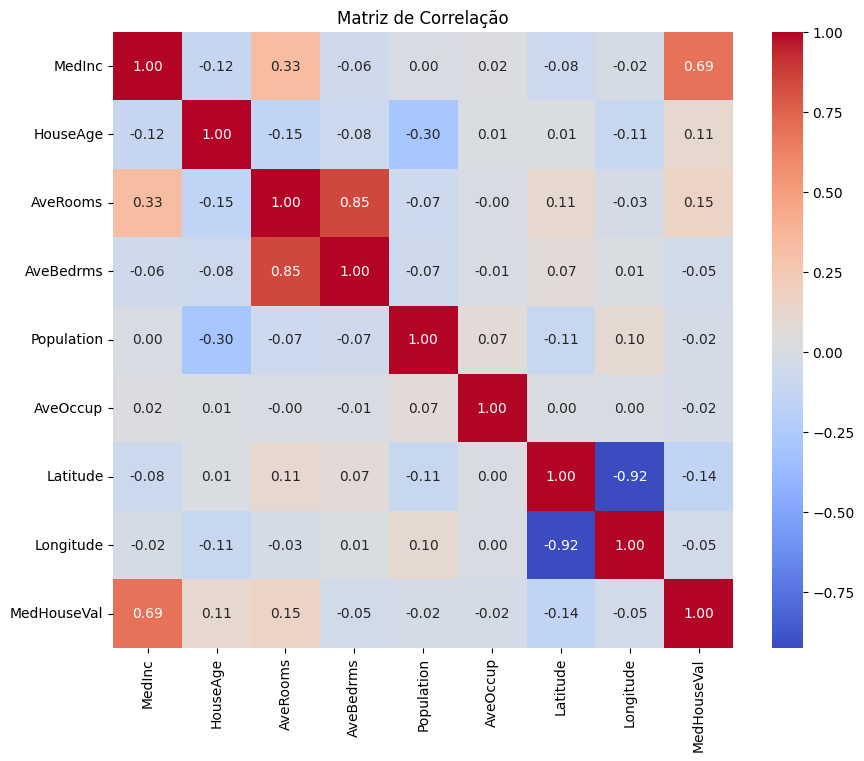

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

# matriz de correlação
matriz_correlacao = df.corr(method='pearson')


plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de Correlação')
plt.show()

### Parte 4: Visualização de Dados
*Gere gráficos para documentar e facilitar a compreensão dos achados:*
1. **Boxplots:** Visualize a distribuição resumida e aponte os outliers encontrados na Parte 2.
2. **Histogramas:** Analise as frequências e o formato das caudas de certas variáveis (confirme os achados de obliquidade da Parte 2).
3. **Scatter Plots (Gráficos de Dispersão):** Construa gráficos associando pares de atributos que se mostraram fortemente correlacionados na Parte 3.

##### 1. Boxplots por variavel

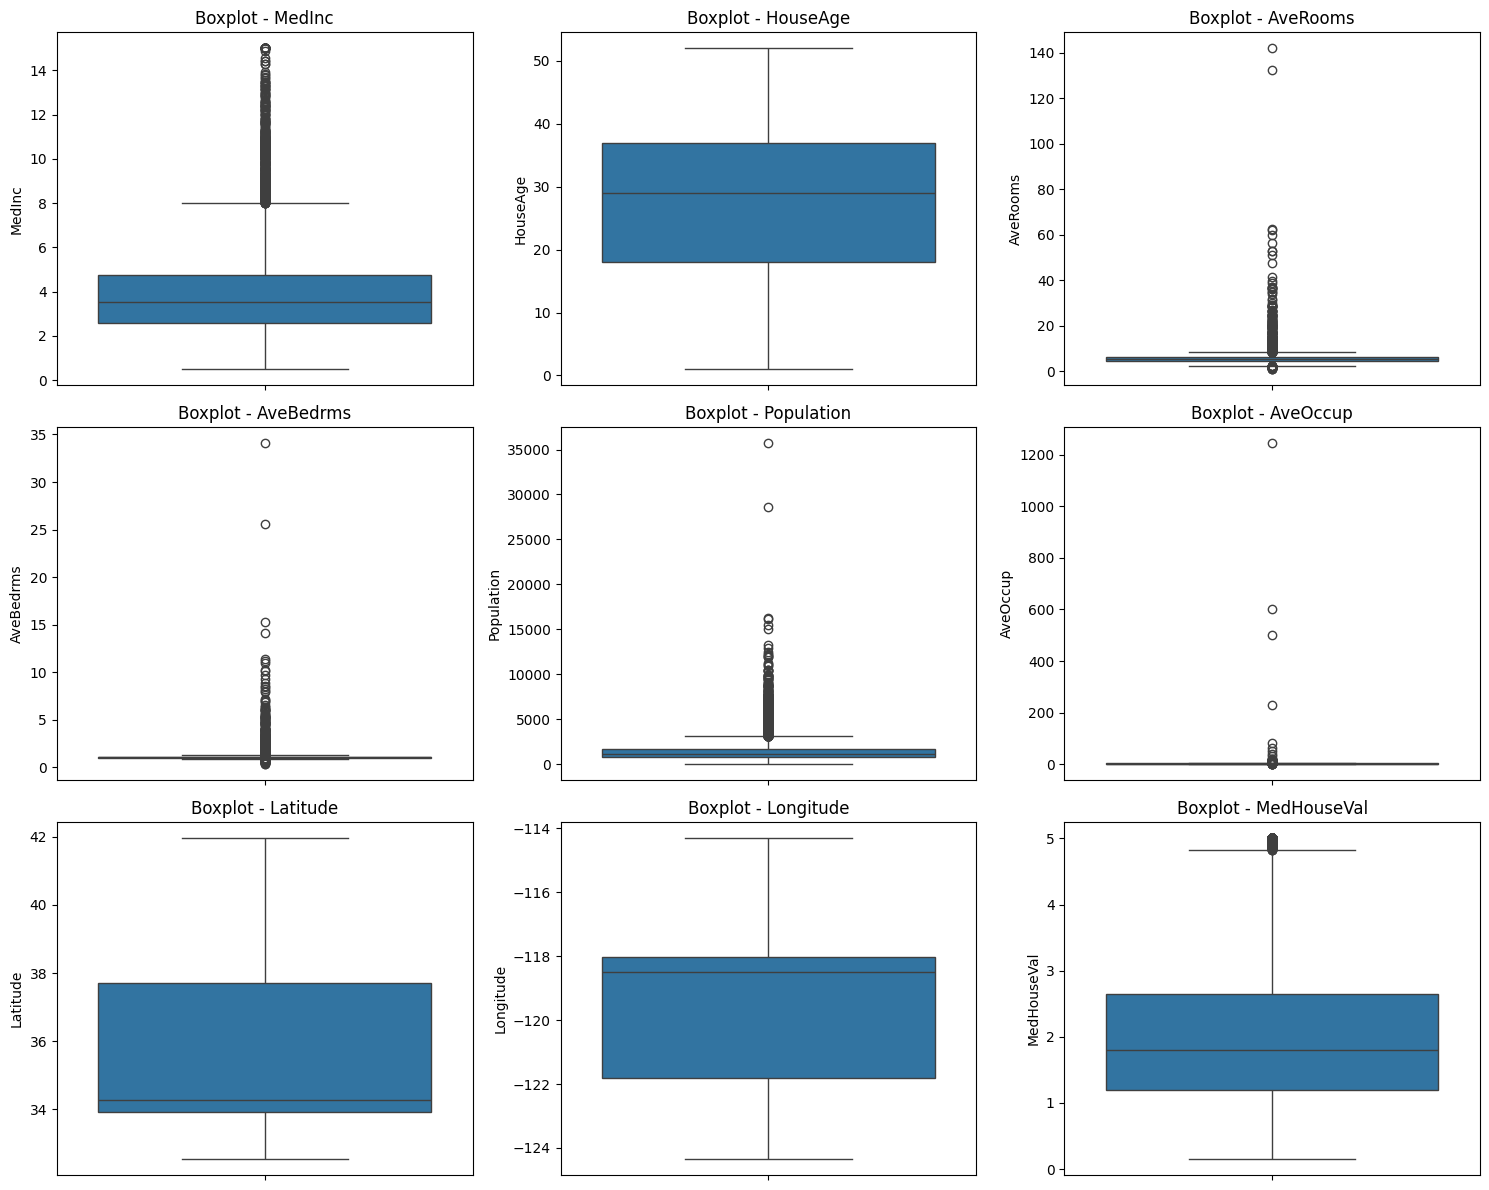

In [63]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(15, 12)
)

axes = axes.flatten()

for i, col in enumerate(df.columns):
    sns.boxplot(
        y=df[col],
        ax=axes[i]
    )

    axes[i].set_title(f'Boxplot - {col}')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()


##### 2. Histogramas

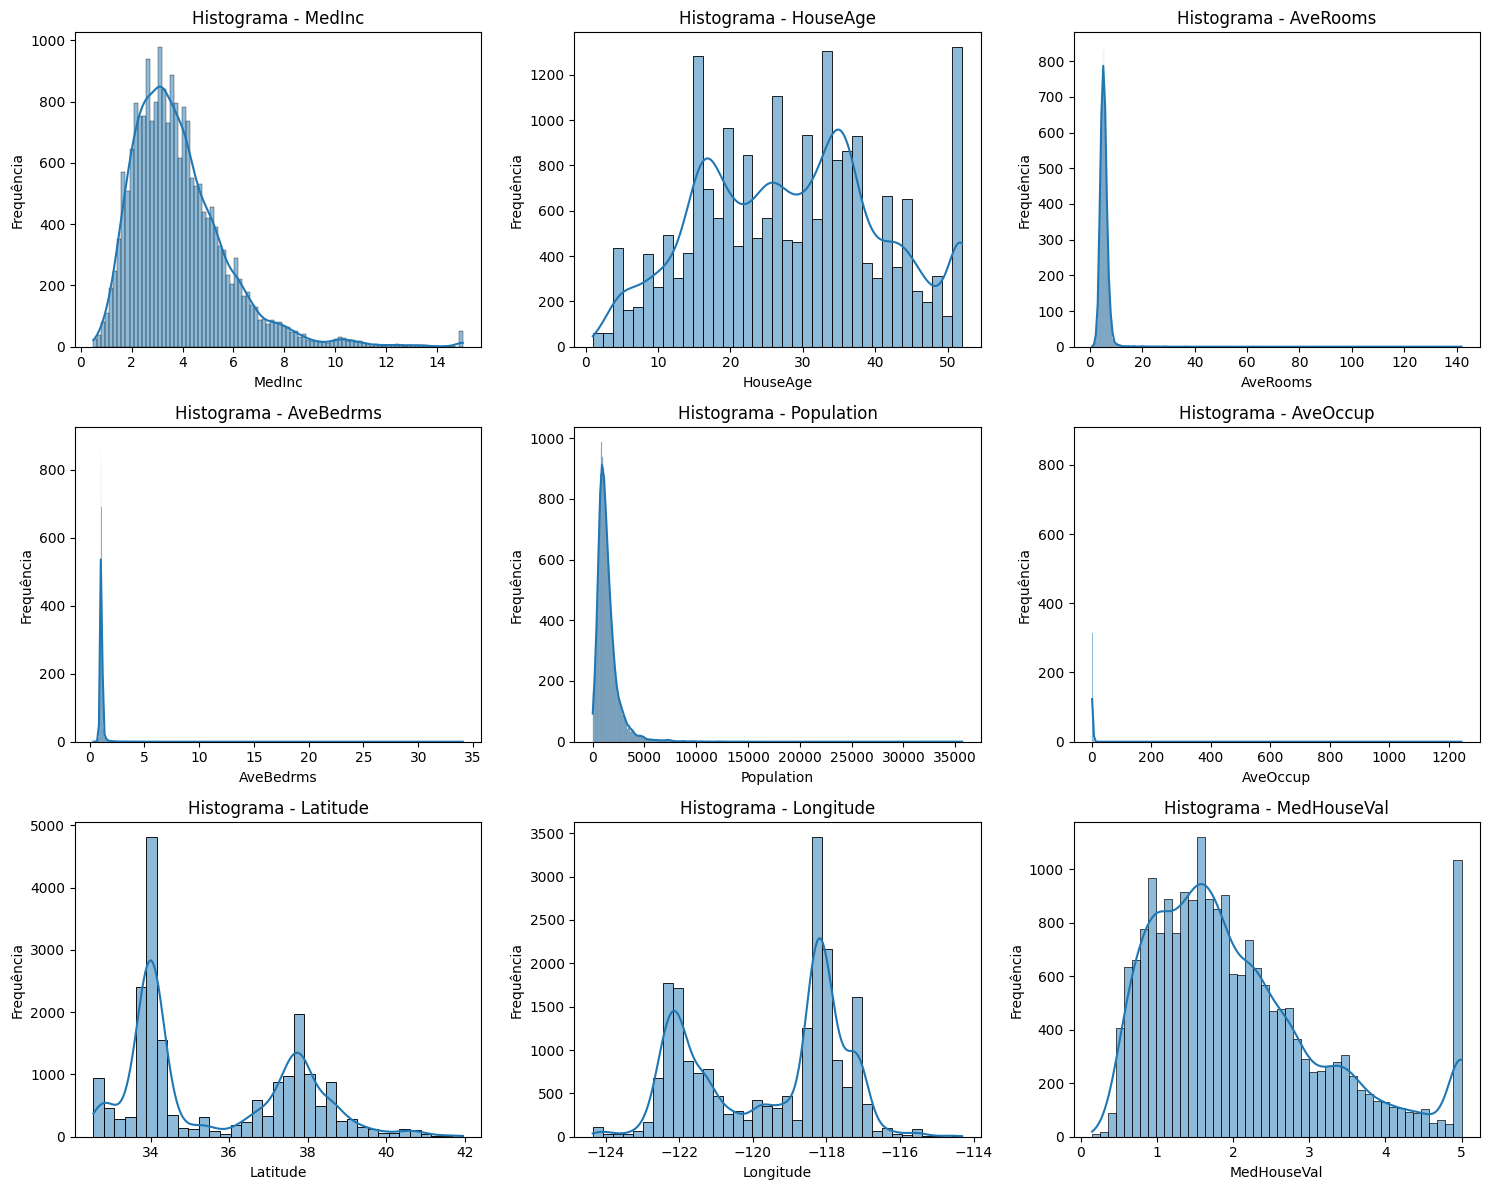

In [65]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(15, 12)
)

axes = axes.flatten()

for i, col in enumerate(df.columns):

    sns.histplot(
        df[col].dropna(),
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Histograma - {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequência')

plt.tight_layout()
plt.show()


##### Scatter Plots

In [66]:
#encontrando quais possuem amior correlacao
correlacao = df.corr()

display(
    correlacao['MedHouseVal']
    .sort_values(ascending=False)
)


,MedHouseVal
MedHouseVal,1.000000
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


In [70]:
#Pegando o tip 3
top_3 = correlacao.head(3).index

print(top_3)


Index(['MedInc', 'HouseAge', 'AveRooms'], dtype='object')


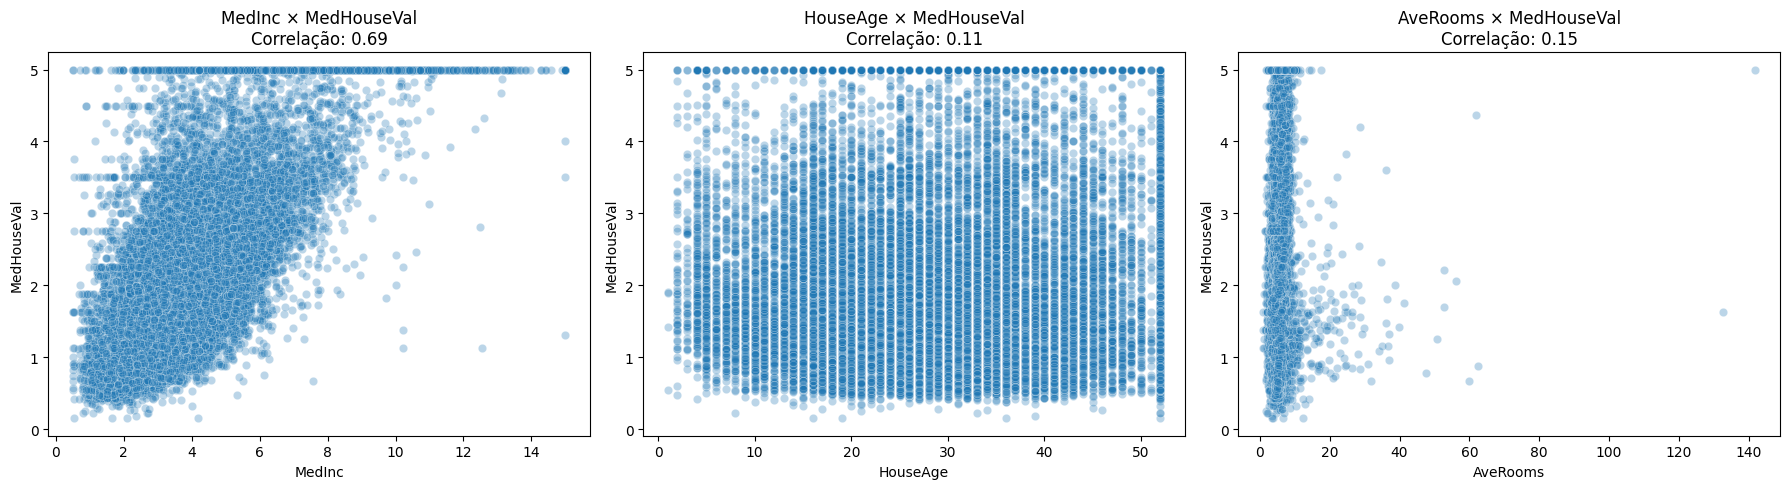

In [71]:
# plotando a correrlacao das 3 variaveis com MedHouseVal
fig, axes = plt.subplots(1,3,figsize=(18, 5))

for i, col in enumerate(top_3):
    sns.scatterplot(
        data=df,
        x=col,
        y='MedHouseVal',
        alpha=0.3,
        ax=axes[i]
    )

    axes[i].set_title(
        f'{col} × MedHouseVal\n'
        f'Correlação: {df[col].corr(df["MedHouseVal"]):.2f}'
    )

plt.tight_layout()
plt.show()